In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("libraries imported successfully!")

libraries imported successfully!


In [ ]:
df=sns.load_dataset("titanic")

print("Dataset loaded successfully!")
print("shape:", df.shape)
df.head()

Dataset loaded successfully!
shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


survived
0    549
1    342
Name: count, dtype: int64


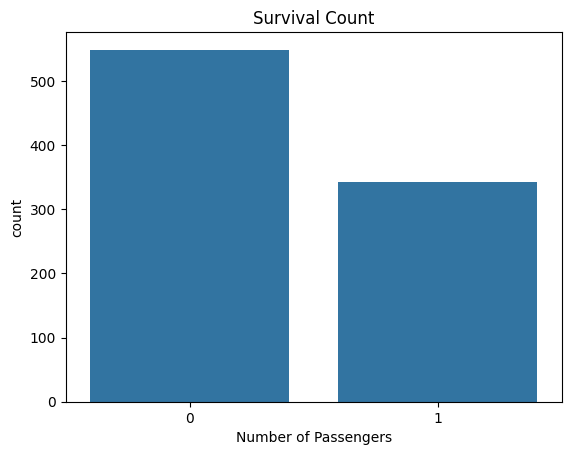

In [ ]:
print(df["survived"].value_counts())

sns.countplot(data=df,x="survived")
plt.title("Survival Count")
plt.xlabel("Survived(0=No,1+Yes)")
plt.xlabel("Number of Passengers")
plt.show()

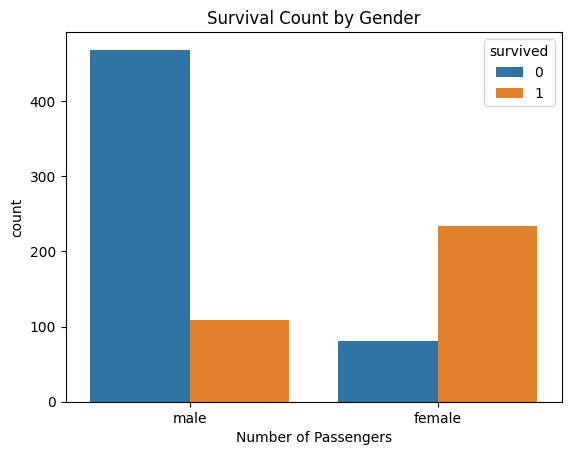

In [ ]:
sns.countplot(data=df, x="sex",hue="survived")
plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.xlabel("Number of Passengers")
plt.show()

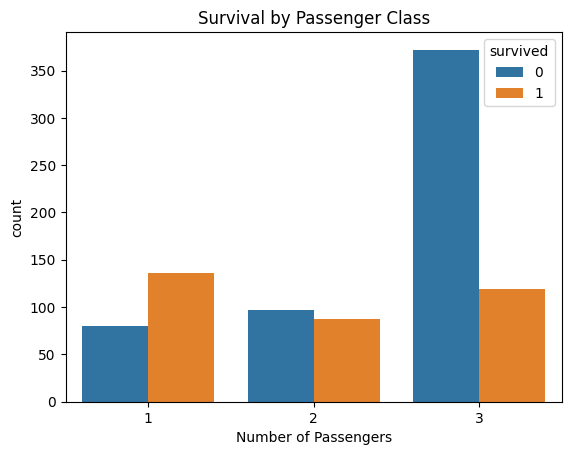

In [ ]:
sns.countplot(data=df, x="pclass",hue="survived")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.xlabel("Number of Passengers")
plt.show()

In [ ]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [ ]:
 features = ["pclass","sex","age","sibsp","parch","fare","embarked"]

 x=df[features].copy()
 y=df["survived"].copy()

 print("Features:")
 print(x.head())

 print("\nTarget:")
 print(y.head())

Features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
    x,y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Traiing data:",X_train.shape)
print("Testing data:",X_test.shape)

Traiing data: (712, 7)
Testing data: (179, 7)


In [ ]:
#Fill missing age
age_median= X_train["age"].median()

X_train["age"]=X_train["age"].fillna(age_median)
X_test["age"]=X_test['age'].fillna(age_median)

#Fill missing embarked
embarked_mode=X_train["embarked"].mode()[0]

X_train["embarked"]=X_train["embarked"].fillna(embarked_mode)
X_test["embarked"]=X_test["embarked"].fillna(embarked_mode)

print("Missing values after cleaning:")
print(X_train.isnull().sum())


Missing values after cleaning:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


In [ ]:
X_train=pd.get_dummies(X_train, columns=["sex","embarked"],drop_first=True)
X_test=pd.get_dummies(X_test, columns=["sex","embarked"],drop_first=True)

#Make sure both datasets have exactly the same columns
X_test=X_test.reindex(columns=X_train.columns, fill_value=0)

print("training column:")
print(X_train.columns.tolist())

print("\nShape ater encoding:")
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)

training column:
['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']

Shape ater encoding:
X_train: (712, 8)
X_test: (179, 8)


In [ ]:
scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print("Scaling completed!")

Scaling completed!


In [ ]:
log_model=LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled,y_train)

y_pred_log=log_model.predict(X_test_scaled)

log_accuracy=accuracy_score(y_test,y_pred)
print("Logistic Regression Accuracy:",round(log_accuracy,4))



Logistic Regression Accuracy: 0.8045


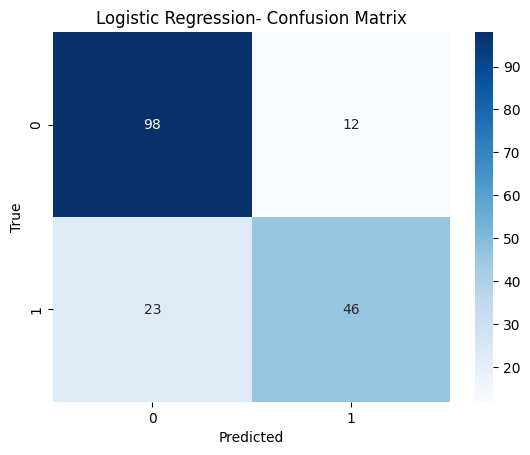

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [ ]:
cm= confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("Logistic Regression- Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

print(classification_report(y_test,y_pred_log))